# Практическая работа 6. Подготовка набора данных


**Предметная задача.** IT-компания ведёт журнал обращений в службу поддержки (service desk): сбои продуктов, нагрузка на серверы, эскалации. По этим данным позже можно учить модель, которая заранее замечает **нарушение SLA** (Service Level Agreement — согласованные с клиентом сроки реакции и решения обращений)(`sla_breached`: 1 — срок ответа сорван, 0 — уложились). В этой работе модель **не строится**. Нужно осмотреть, посчитать, нарисовать и привести таблицу в порядок — как на практиках 1–5.

Официальная формулировка занятия: загрузка → разведочный анализ и визуализация → предобработка → конструирование признаков. У нас те же шаги разложены на **пять блоков**, по одной пройденной практике.

---

### Что входит в работу (14 баллов)

| Блок | Практика | Что сдаёте | Баллы |
|------|----------|------------|------:|
| 1 | Основы pandas | код осмотра, выборки и нового столбца + вопросы | 2,5 |
| 2 | NumPy | код на массивах (срез, маска, broadcasting) + вопросы | 2,5 |
| 3 | Группировка | `groupby`, `pivot_table`, дата из Unix + вопросы | 3 |
| 4 | Визуализация | не меньше 4 графиков разных типов и выводы | 3 |
| 5 | Подготовка данных | пропуски, текст, кодирование, масштаб, новые признаки + вопросы | 3 |
| | | **Итого** | **14** |



## Шаг 0. Персонализация


In [1]:
# ==========================================================
# ⬇️  ЗАПОЛНИТЕ ЭТИ ТРИ ПОЛЯ СВОИМИ ДАННЫМИ
# ==========================================================
last_name   = "Бокерия"    # <-- впишите свою фамилию
first_name  = "Полина"     # <-- впишите своё имя
list_number = 4            # <-- ваш номер по списку (целое число)
# ==========================================================

import hashlib

def make_seed(last: str, first: str, number: int) -> int:
    # ФИО + номер -> стабильный seed 0..99999
    key = f"{last.strip().lower()}|{first.strip().lower()}|{int(number)}"
    return int(hashlib.sha256(key.encode("utf-8")).hexdigest(), 16) % 100_000

SEED = make_seed(last_name, first_name, list_number)

print("Студент:", last_name, first_name, f"(№{list_number})")
print("Ваш персональный SEED:", SEED)
print("Запишите SEED в итоговый отчёт — он подтверждает вариант.")


Студент: Бокерия Полина (№4)
Ваш персональный SEED: 92977
Запишите SEED в итоговый отчёт — он подтверждает вариант.


> **Как это работает.** `hashlib.sha256` переводит строку с ФИО и номером в большое число, затем берётся остаток от деления на 100 000. Одинаковые ФИО и номер всегда дают один и тот же SEED, разные — почти всегда разный. Весь датасет ниже зависит только от этого числа.


## Подготовка окружения



In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)


## Генерация набора данных


**Признаки**

| Столбец | Смысл |
|---------|-------|
| `ticket_id` | идентификатор обращения |
| `opened_ts` | время открытия в Unix-секундах |
| `department` | отдел: Support, Backend, DevOps, Security, Data |
| `product` | продукт: Cloud, CRM, Billing, Auth, Analytics |
| `priority` | приоритет: Low, Medium, High, Critical |
| `channel` | канал: Email, Slack, Portal, Phone |
| `assignee_level` | уровень исполнителя: Junior, Middle, Senior |
| `client_tier` | тариф клиента: Free, Pro, Enterprise |
| `cpu_pct` | загрузка CPU на затронутом узле, % |
| `memory_mb` | занятая память, МБ |
| `n_reopens` | сколько раз тикет открывали повторно |
| `comments` | число комментариев в тикете |
| `resolve_hours` | часы до закрытия |
| **`sla_breached`** | **цель**: 1 — SLA нарушен, 0 — нет |


In [3]:
#@title Создание персонального датасета { display-mode: "form" }

def load_it_tickets(seed: int, n: int = 1800) -> "pd.DataFrame":
    """Индивидуальный «грязный» журнал IT-обращений по seed."""
    rng = np.random.default_rng(seed)

    opened_ts = rng.integers(1_735_689_600, 1_751_241_600, size=n)
    department = rng.choice(
        ["Support", "Backend", "DevOps", "Security", "Data"],
        size=n, p=[0.32, 0.22, 0.18, 0.14, 0.14],
    )
    product = rng.choice(
        ["Cloud", "CRM", "Billing", "Auth", "Analytics"], size=n
    )
    priority = rng.choice(
        ["Low", "Medium", "High", "Critical"], size=n, p=[0.40, 0.30, 0.20, 0.10]
    )
    channel = rng.choice(["Email", "Slack", "Portal", "Phone"], size=n)
    assignee = rng.choice(["Junior", "Middle", "Senior"], size=n, p=[0.35, 0.45, 0.20])
    tier = rng.choice(["Free", "Pro", "Enterprise"], size=n, p=[0.45, 0.40, 0.15])
    cpu_pct = np.clip(np.round(rng.normal(48, 18, size=n), 1), 1, 99)
    memory_mb = np.clip(np.round(rng.normal(2200, 850, size=n), 0), 256, None)
    n_reopens = rng.poisson(0.7, size=n)
    comments = rng.poisson(4.0, size=n) + 1
    resolve_hours = np.clip(np.round(rng.lognormal(1.55, 0.75, size=n), 2), 0.2, 240)

    logit = (
        -1.4
        + 1.4 * (priority == "Critical")
        + 0.7 * (priority == "High")
        - 0.4 * (priority == "Low")
        + 0.035 * resolve_hours
        + 0.018 * cpu_pct
        + 0.55 * (department == "Security")
        + 0.35 * (n_reopens >= 2)
        - 0.45 * (assignee == "Senior")
        - 0.30 * (tier == "Enterprise")
    )
    sla = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({
        "ticket_id": np.arange(10_000, 10_000 + n),
        "opened_ts": opened_ts,
        "department": department,
        "product": product,
        "priority": priority,
        "channel": channel,
        "assignee_level": assignee,
        "client_tier": tier,
        "cpu_pct": cpu_pct,
        "memory_mb": memory_mb,
        "n_reopens": n_reopens,
        "comments": comments,
        "resolve_hours": resolve_hours,
        "sla_breached": sla,
    })

    df.loc[rng.choice(n, int(0.06 * n), replace=False), "resolve_hours"] = np.nan
    df.loc[rng.choice(n, int(0.04 * n), replace=False), "cpu_pct"] = np.nan
    df.loc[rng.choice(n, int(0.03 * n), replace=False), "comments"] = np.nan
    df.loc[rng.choice(n, 10, replace=False), "resolve_hours"] *= 9
    df.loc[rng.choice(n, 8, replace=False), "memory_mb"] *= 7
    ridx = rng.choice(n, int(0.12 * n), replace=False)
    df.loc[ridx, "department"] = df.loc[ridx, "department"].str.upper()
    pidx = rng.choice(n, int(0.08 * n), replace=False)
    df.loc[pidx, "product"] = "  " + df.loc[pidx, "product"].str.lower() + " "
    df = pd.concat([df, df.sample(int(0.025 * n), random_state=seed)], ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

print("Функция load_it_tickets готова.")


Функция load_it_tickets готова.


Загрузка набора:


In [4]:
df_raw = load_it_tickets(SEED)

print("Ваш датасет создан. Размер:", df_raw.shape)
print("Доля нарушений SLA:", f"{df_raw['sla_breached'].mean():.1%}")


Ваш датасет создан. Размер: (1845, 14)
Доля нарушений SLA: 45.8%


---
# Этап 1. Основы pandas (практика 1)

**Цель.** Убедиться, что таблица загрузилась, понять размер и типы, выбрать строки и столбцы, добавить признак, сохранить фрагмент.

### Пример

Стандартный осмотр и простая выборка.


In [5]:
print("Размер (строки, столбцы):", df_raw.shape)
print("Имена столбцов:", list(df_raw.columns))
print("\nПервые 5 строк:")
display(df_raw.head())
print("\nТипы и непропуски:")
df_raw.info()


Размер (строки, столбцы): (1845, 14)
Имена столбцов: ['ticket_id', 'opened_ts', 'department', 'product', 'priority', 'channel', 'assignee_level', 'client_tier', 'cpu_pct', 'memory_mb', 'n_reopens', 'comments', 'resolve_hours', 'sla_breached']

Первые 5 строк:


,ticket_id,opened_ts,department,product,priority,channel,assignee_level,client_tier,cpu_pct,memory_mb,n_reopens,comments,resolve_hours,sla_breached
0,10485,1743525663,Security,Billing,High,Portal,Middle,Free,53.9,1089.0,1,6.0,16.96,1
1,11236,1743069945,Backend,cloud,Medium,Email,Junior,Enterprise,NaN,1333.0,0,5.0,NaN,1
2,10048,1747041230,Security,Auth,Critical,Portal,Junior,Pro,40.4,2922.0,1,5.0,0.86,1
3,10913,1744020673,SUPPORT,auth,Medium,Slack,Middle,Pro,40.9,2459.0,0,5.0,3.94,0
4,10469,1736452035,Support,Cloud,Medium,Phone,Junior,Pro,53.6,2170.0,1,3.0,7.56,1



Типы и непропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1845 entries, 0 to 1844
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ticket_id       1845 non-null   int64  
 1   opened_ts       1845 non-null   int64  
 2   department      1845 non-null   object 
 3   product         1845 non-null   object 
 4   priority        1845 non-null   object 
 5   channel         1845 non-null   object 
 6   assignee_level  1845 non-null   object 
 7   client_tier     1845 non-null   object 
 8   cpu_pct         1772 non-null   float64
 9   memory_mb       1845 non-null   float64
 10  n_reopens       1845 non-null   int64  
 11  comments        1790 non-null   float64
 12  resolve_hours   1733 non-null   float64
 13  sla_breached    1845 non-null   int64  
dtypes: float64(4), int64(4), object(6)
memory usage: 201.9+ KB


In [6]:
# loc — по подписям, iloc — по номерам
print("Один столбец (первые значения priority):")
print(df_raw["priority"].head())
print("\nДве строки и три столбца через loc:")
display(df_raw.loc[0:1, ["ticket_id", "department", "priority"]])
print("Критические тикеты:", (df_raw["priority"] == "Critical").sum())


Один столбец (первые значения priority):
0        High
1      Medium
2    Critical
3      Medium
4      Medium
Name: priority, dtype: object

Две строки и три столбца через loc:


,ticket_id,department,priority
0,10485,Security,High
1,11236,Backend,Medium


Критические тикеты: 171


### Задание 1

В ячейках ниже, **на своих данных**:

1. Выведите **последние 8 строк** (`.tail(8)`).
2. Посчитайте **число полных дубликатов** (`.duplicated().sum()`).
3. Через `.loc` отберите тикеты с `priority` равным `"High"` **или** `"Critical"` и столбцы `ticket_id`, `department`, `priority`, `resolve_hours`. Сколько таких строк?
4. Добавьте столбец `is_slow`: `True`, если `resolve_hours` больше 24 (пропуски пусть останутся пропусками). Затем **переименуйте** `n_reopens` в `reopen_count`.
5. Сохраните первые 100 строк текущего `df_raw` в файл `it_tickets_head.csv`.


In [7]:
# ▼▼▼ ВАШ КОД (Задание 1) ▼▼▼

# 1. Последние 8 строк

df_raw.tail(8)

,ticket_id,opened_ts,department,product,priority,channel,assignee_level,client_tier,cpu_pct,memory_mb,n_reopens,comments,resolve_hours,sla_breached
1837,10639,1747212245,Support,CRM,Low,Portal,Middle,Free,30.6,2013.0,1,9.0,2.51,0
1838,10624,1739099637,DevOps,Cloud,High,Email,Senior,Pro,63.4,2679.0,1,5.0,7.96,0
1839,10709,1744169506,DEVOPS,analytics,Low,Phone,Middle,Free,31.2,1978.0,1,3.0,1.54,0
1840,10934,1739012844,DevOps,Auth,Medium,Email,Middle,Free,35.3,1785.0,1,5.0,3.82,0
1841,10986,1748828750,Support,CRM,High,Slack,Middle,Pro,33.6,1845.0,1,4.0,3.91,0
1842,10614,1736719948,Backend,Analytics,Low,Slack,Junior,Free,58.1,2024.0,2,3.0,5.07,1
1843,11466,1744814980,DevOps,Cloud,Low,Phone,Middle,Pro,54.8,2020.0,0,4.0,10.01,0
1844,10176,1738547595,BACKEND,Billing,Medium,Email,Middle,Pro,88.7,1210.0,0,7.0,2.71,0


In [8]:
# 2. Число дубликатов
n_dups = df_raw.duplicated().sum()
print("Число полных дубликатов:", n_dups)

Число полных дубликатов: 45


In [9]:
# 3. High или Critical, выбранные столбцы
mask = (df_raw["priority"] == "High") | (df_raw["priority"] == "Critical")

subset = df_raw.loc[mask, ["ticket_id", "department", "priority", "resolve_hours"]]

print("Таких строк:", len(subset))
subset.head()

Таких строк: 598


,ticket_id,department,priority,resolve_hours
0,10485,Security,High,16.96
2,10048,Security,Critical,0.86
6,10166,Security,Critical,14.46
10,10891,Support,High,7.16
14,10088,Support,High,2.39


In [10]:
# 4. Столбец is_slow и переименование n_reopens → reopen_count

# resolve_hours > 24 — для NaN даёт False, но по заданию NaN должны остаться NaN.
# Поэтому строим как «object» с NaN там, где resolve_hours пусто:
df_raw["is_slow"] = df_raw["resolve_hours"].apply(
    lambda x: (x > 24) if pd.notna(x) else np.nan
)

# Переименование
df_raw = df_raw.rename(columns={"n_reopens": "reopen_count"})

print("is_slow — уникальные значения:", df_raw["is_slow"].unique()[:5])
print("reopen_count в столбцах:", "reopen_count" in df_raw.columns)
df_raw[["resolve_hours", "is_slow", "reopen_count"]].head()

is_slow — уникальные значения: [False nan True]
reopen_count в столбцах: True


,resolve_hours,is_slow,reopen_count
0,16.96,False,1
1,NaN,NaN,0
2,0.86,False,1
3,3.94,False,0
4,7.56,False,1


In [11]:
# 5. Сохранение it_tickets_head.csv
df_raw.head(100).to_csv("it_tickets_head.csv", index=False)
print("Сохранено: it_tickets_head.csv (100 строк, без индекса)")
# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲


Сохранено: it_tickets_head.csv (100 строк, без индекса)


**Контрольные вопросы к этапу 1** (ответьте текстом):

1. Чем `.info()` отличается от `.describe()`? Что показывает каждый?
2. Когда удобнее `.loc`, а когда `.iloc`?
3. Почему дубликаты строк могут испортить и статистику, и будущую модель?


*Ответы:*

1. .info() и .describe() показывают разное. Первый описывает структуру таблицы: сколько строк и столбцов, как называются поля, какие у них типы, сколько в каждом непустых значений и сколько всё это занимает памяти. Это «паспорт» данных — по нему сразу видно, всё ли загрузилось, нет ли чисел, записанных как текст, и где есть пропуски. Второй считает статистики только по числовым столбцам: количество значений, среднее, стандартное отклонение, минимум, квартили и максимум. Это уже «содержимое» — по нему видно диапазон, разброс и возможные выбросы, когда максимум резко отрывается от верхнего квартиля. Текстовые столбцы в .describe() по умолчанию не попадают, для них нужен отдельный вызов с include="object".

2. .loc и .iloc отличаются способом доступа. .loc работает по подписям — по именам столбцов и меткам индекса. df.loc[0:4, "temp"] берёт строки с метками от 0 до 4 включительно и столбец temp. .loc удобен для фильтра по условию: df.loc[df["priority"] == "High", ["ticket_id", "department"]] одновременно фильтрует строки и выбирает столбцы по именам. .iloc работает по позициям, как срезы в Python: df.iloc[0:5, 0:3] — первые пять строк и первые три столбца, правая граница не включается. .iloc удобнее, когда имена неизвестны заранее, когда нужны «первые N строк» или универсальный код с меняющимися столбцами. loc — это label, iloc — integer position.

3. Дубликаты портят и статистику, и модель. В статистике повторяющиеся строки работают как искусственное усиление веса: если один и тот же тикет записан пять раз, он в пять раз сильнее влияет на среднее и доли. Искажаются частоты категорий — задвоенный отдел выглядит популярнее, чем есть, — смещаются корреляции, если задвоены крайние значения, и сужаются доверительные интервалы, потому что формально выборка больше, чем на самом деле. В модели главная проблема — утечка: при случайном делении на train и test копия одной строки легко попадает в обе части, и модель запоминает конкретный пример вместо закономерности. Метрики на тесте завышаются, а на новых данных модель работает плохо. Плюс переобучение — модель видит одну и ту же ситуацию многократно — и перекос классов, если задвоены именно нарушения SLA. Поэтому дубликаты удаляют до разведки, обучения и оценки, как в этапе 5 через df.drop_duplicates().


---
# Этап 2. NumPy

**Цель.** Перевести столбец в массив, посчитать агрегаты без цикла `for`, срезать, отфильтровать маской, сделать поэлементную операцию (broadcasting).

Таблица удобна, когда у столбцов есть имена. Массив удобен, когда нужно быстро посчитать «все значения сразу».


### Пример


In [12]:
cpu = df_raw["cpu_pct"].to_numpy(dtype=float)
print("Тип:", type(cpu), "форма:", cpu.shape, "dtype:", cpu.dtype)
print("Первые 8 значений:", cpu[:8])
print("Среднее без учёта NaN:", np.nanmean(cpu))
print("Максимум:", np.nanmax(cpu))

# маска: загрузка выше 80% (NaN даст False)
high_cpu = cpu > 80
print("Доля наблюдений с CPU > 80%:", np.nanmean(high_cpu))

# broadcasting: перевод % в долю 0..1
cpu_share = cpu / 100
print("Доля CPU, первые 5:", cpu_share[:5])


Тип: <class 'numpy.ndarray'> форма: (1845,) dtype: float64
Первые 8 значений: [53.9  nan 40.4 40.9 53.6 72.7 50.9  nan]
Среднее без учёта NaN: 47.665462753950344
Максимум: 99.0
Доля наблюдений с CPU > 80%: 0.02926829268292683
Доля CPU, первые 5: [0.539   nan 0.404 0.409 0.536]


### Задание 2

Работайте с массивами, не с циклами `for` по строкам.

1. Соберите массивы `hours` из `resolve_hours` и `mem` из `memory_mb` (тип `float`).
2. Посчитайте **медиану** и **стандартное отклонение** `hours`, игнорируя NaN.
3. Срезом возьмите **последние 15** значений `mem`.
4. Постройте маску «память выше 4000 МБ» и выведите, **сколько** таких тикетов (для NaN считайте «не выше»).
5. Сделайте z-оценку памяти через broadcasting: `(mem - mean) / std`, где mean и std без NaN. Выведите 5 первых z-оценок.


In [13]:
# ▼▼▼ ВАШ КОД (Задание 2) ▼▼▼

# 1. Массивы hours и mem
hours = df_raw["resolve_hours"].to_numpy(dtype=float)
mem = df_raw["memory_mb"].to_numpy(dtype=float)

print("hours:", hours.shape, hours.dtype)
print("mem:  ", mem.shape, mem.dtype)

hours: (1845,) float64
mem:   (1845,) float64


In [14]:
# 2. Медиана и std для hours
med_hours = np.nanmedian(hours)
std_hours = np.nanstd(hours)

print("Медиана hours (без NaN):", med_hours)
print("Std hours (без NaN):    ", std_hours)

Медиана hours (без NaN): 4.68
Std hours (без NaN):     11.008520374530644


In [15]:
# 3. Срез последних 15 значений mem
mem_last15 = mem[-15:]
print("Последние 15 значений mem:")
print(mem_last15)

Последние 15 значений mem:
[ 379. 1942. 3302. 2184. 2128. 2856. 3323. 2013. 2679. 1978. 1785. 1845.
 2024. 2020. 1210.]


In [16]:
# 4. Маска памяти > 4000
mask_mem = mem > 4000
print("Тикетов с памятью > 4000 МБ:", int(mask_mem.sum()))

Тикетов с памятью > 4000 МБ: 45


In [17]:
# 5. Z-оценка памяти
mu = np.nanmean(mem)
sigma = np.nanstd(mem)

mem_z = (mem - mu) / sigma
print("mean и std без NaN:", mu, sigma)
print("Первые 5 z-оценок:")
print(mem_z[:5])
# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲


mean и std без NaN: 2245.1132791327914 1219.7777938217394
Первые 5 z-оценок:
[-0.94780647 -0.74777003  0.55492625  0.17534892 -0.06157948]


**Контрольные вопросы к этапу 2:**

1. Чем массив NumPy принципиально отличается от списка Python?
2. Что такое broadcasting? Приведите пример из этого задания.
3. Почему для среднего по столбцу с пропусками нужен `np.nanmean`, а не `np.mean`?


*Ответы:*

1. Массив NumPy принципиально отличается от списка Python тем, как он хранит данные и как выполняет операции. Список — это массив ссылок на объекты Python, каждый элемент лежит отдельно в памяти, и любая арифметика над списком идёт через цикл интерпретатора: элемент за элементом. Массив NumPy хранит числа одного типа подряд в непрерывном блоке памяти, а операции над ним выполняются скомпилированным кодом сразу надо всем массивом. Поэтому arr * 2 на миллионе элементов работает в десятки раз быстрее, чем цикл по списку, но ценой этого становится жёсткое требование: все элементы одного типа, форма фиксирована, а гибкость списка — с разнотипными элементами и произвольной длиной — теряется.

2. Broadcasting — это механизм, при котором NumPy автоматически «растягивает» меньший массив (или скаляр) до формы большего, чтобы операция применилась поэлементно, без явного цикла. В этом задании broadcasting сработал в z-оценке: (mem - mu) / sigma, где mu и sigma — обычные числа, полученные через np.nanmean и np.nanstd, а mem — массив. NumPy не требует создавать массив из mu и sigma, он сам подставляет скаляр в каждую ячейку. Другой пример — из примера выше: cpu_share = cpu / 100, где деление на скаляр даёт массив долей.

3. np.nanmean нужен вместо np.mean, потому что любая арифметическая операция с NaN даёт NaN, и np.mean по массиву с пропусками вернёт nan, потеряв всю информацию о среднем. np.nanmean специально устроен так, чтобы игнорировать NaN и считать среднее по оставшимся значениям. То же самое с np.nanmedian, np.nanstd, np.nansum — у каждой обычной агрегатной функции есть «нан-версия». В нашем датасете в resolve_hours и cpu_pct специально заложены пропуски, поэтому без нан-версий почти все агрегаты превратились бы в nan.


---
# Этап 3. Агрегирование и группировка (практика 3)

**Цель.** Ответить на вопросы вида «какая доля нарушений SLA **в каждом** отделе?» без ручного фильтра. Схема одна: разбить → посчитать → собрать.

Unix-время `opened_ts` нужно превратить в обычную дату, иначе группировка по дням невозможна.


### Пример


In [18]:
print("Среднее время решения по приоритету:")
display(
    df_raw.groupby("priority")["resolve_hours"].agg(["count", "mean", "median"]).round(2)
)

print("\nСводная: доля нарушений SLA по отделу и уровню исполнителя")
pivot = pd.pivot_table(
    df_raw, values="sla_breached", index="department",
    columns="assignee_level", aggfunc="mean",
)
display(pivot.round(3))


Среднее время решения по приоритету:


,count,mean,median
priority,,,
Critical,156,7.20,4.92
High,404,5.90,4.42
Low,679,7.24,4.89
Medium,494,6.63,4.66



Сводная: доля нарушений SLA по отделу и уровню исполнителя


assignee_level,Junior,Middle,Senior
department,,,
BACKEND,0.692,0.286,0.714
Backend,0.477,0.431,0.373
DATA,0.455,0.438,0.500
DEVOPS,0.450,0.750,0.600
Data,0.436,0.464,0.341
DevOps,0.500,0.423,0.362
SECURITY,0.556,0.588,0.714
SUPPORT,0.440,0.406,0.333
Security,0.551,0.487,0.458


In [19]:
df_time = df_raw.copy()
df_time["opened_at"] = pd.to_datetime(df_time["opened_ts"], unit="s")
print("Минимум и максимум даты:", df_time["opened_at"].min(), df_time["opened_at"].max())
print("Тикетов по месяцам:")
print(df_time.groupby(df_time["opened_at"].dt.to_period("M")).size())


Минимум и максимум даты: 2025-01-01 00:11:38 2025-06-29 22:34:34
Тикетов по месяцам:
opened_at
2025-01    302
2025-02    279
2025-03    316
2025-04    334
2025-05    325
2025-06    289
Freq: M, dtype: int64


### Задание 3

1. Сделайте `groupby` по `product`: для каждого продукта — число тикетов, среднее `cpu_pct`, доля `sla_breached`. Отсортируйте по доле нарушений **по убыванию**.
2. Постройте `pivot_table`: строки — `channel`, столбцы — `priority`, значения — среднее `resolve_hours`.
3. Переведите `opened_ts` в datetime. Добавьте столбец `opened_date` (только дата). Посчитайте число тикетов **по дням** и выведите 5 дней с наибольшим числом обращений.
4. Дополнительно: `groupby` по `client_tier` с `.agg` сразу по нескольким столбцам — среднее `resolve_hours` и сумма `sla_breached`.


In [20]:
# ▼▼▼ ВАШ КОД (Задание 3) ▼▼▼

# 1. groupby по product
by_product = (
    df_raw.groupby("product")
    .agg(
        tickets=("ticket_id", "count"),
        cpu_mean=("cpu_pct", "mean"),
        sla_rate=("sla_breached", "mean"),
    )
    .sort_values("sla_rate", ascending=False)
    .round(3)
)
display(by_product)

,tickets,cpu_mean,sla_rate
product,,,
cloud,31,46.964,0.516
Billing,329,47.361,0.483
Cloud,345,49.271,0.467
Analytics,334,47.724,0.461
CRM,357,46.043,0.451
Auth,334,48.043,0.446
auth,32,45.363,0.438
billing,29,47.237,0.379
analytics,32,50.773,0.375


In [21]:
# 2. pivot_table channel × priority
pivot_ch = pd.pivot_table(
    df_raw,
    values="resolve_hours",
    index="channel",
    columns="priority",
    aggfunc="mean",
)
display(pivot_ch.round(2))

priority,Critical,High,Low,Medium
channel,,,,
Email,7.18,5.85,6.43,7.10
Phone,5.96,5.56,8.73,6.75
Portal,8.76,5.72,7.54,6.39
Slack,7.11,6.52,6.40,6.39


In [22]:
# 3. Дата из Unix и топ-5 дней
df_time = df_raw.copy()
df_time["opened_at"] = pd.to_datetime(df_time["opened_ts"], unit="s")
df_time["opened_date"] = df_time["opened_at"].dt.date

top_days = df_time["opened_date"].value_counts().head(5)
print("Топ-5 дней по числу тикетов:")
print(top_days)

Топ-5 дней по числу тикетов:
opened_date
2025-01-23    20
2025-04-04    19
2025-03-17    18
2025-03-30    17
2025-05-02    17
Name: count, dtype: int64


In [23]:
# 4. Несколько агрегатов по client_tier
by_tier = df_raw.groupby("client_tier").agg(
    resolve_mean=("resolve_hours", "mean"),
    sla_sum=("sla_breached", "sum"),
)
display(by_tier.round(2))
# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲


,resolve_mean,sla_sum
client_tier,,
Enterprise,6.44,112
Free,6.29,394
Pro,7.41,339


**Контрольные вопросы к этапу 3:**

1. Чем `groupby` отличается от `pivot_table`? Когда что удобнее?
2. Что делает `agg` со словарём нескольких функций?
3. Почему Unix-секунды нельзя сразу группировать «по месяцу», не переводя в datetime?


*Ответы:*

1. groupby и pivot_table решают похожую задачу — разбить таблицу на группы и посчитать в каждой агрегат, — но дают разный формат результата, и от этого зависит, где что удобнее. groupby возвращает «длинную» таблицу, где каждая группа — отдельная строка (а если группировка по нескольким признакам, получается MultiIndex). С такой таблицей удобно дальше работать: сортировать по агрегату, фильтровать, объединять с другими таблицами. pivot_table разворачивает результат в «широкую» сетку «строка × столбец»: одна переменная идёт в индекс, другая — в столбцы, а в ячейках лежит агрегат. Это удобнее для отчёта и для графиков — например, для тепловой карты или сгруппированной столбчатой диаграммы. Если нужно «посчитать и потом фильтровать», лучше использовать groupby; если нужно «сравнить две категории в сетке», удобнее pivot_table. Технически pivot_table внутри часто строит тот же groupby и потом вызывает unstack.

2. Метод agg со словарём нескольких функций позволяет за один проход применить разные функции к разным столбцам. Вместо того чтобы отдельно считать df["resolve_hours"].mean() и df["sla_breached"].sum(), в .agg передается словарь вида {"resolve_hours": "mean", "sla_breached": "sum"} — pandas вернёт таблицу, где для каждой группы посчитаны обе величины. В современном синтаксисе «named aggregation» с кортежами (resolve_mean=("resolve_hours", "mean")) результат получается с понятными именами столбцов, а не с иерархическим MultiIndex — это удобнее читать и потом ссылаться в отчёте. Смысл один: не делать несколько проходов по данным ради нескольких разных агрегатов.

3. Unix-секунды — это одно большое целое или дробное число, количество секунд, прошедших с 1 января 1970 года. В нём самом нет полей «день», «месяц» или «час» — это просто монотонно возрастающая величина. Если попытаться группировать по такому числу напрямую, каждая секунда станет отдельной группой, и никакого смысла в этом не будет. Чтобы получить осмысленные категории, число нужно превратить в datetime-объект: pd.to_datetime(ts, unit="s") даёт полноценную дату со всеми полями, после чего через .dt доступны .dt.date, .dt.hour, .dt.to_period("M") и так далее. И только после этого можно группировать «по дням» или «по месяцам».


---
# Этап 4. Визуализация (практика 4) — 3 балла

**Цель.** Увидеть форму распределения, выброс, связь признаков с `sla_breached`. Таблица среднее не покажет: одинаковое среднее бывает при разной форме гистограммы.

Подписывайте оси и заголовок (`plt.title("Рис. N. ...")`).


### Пример


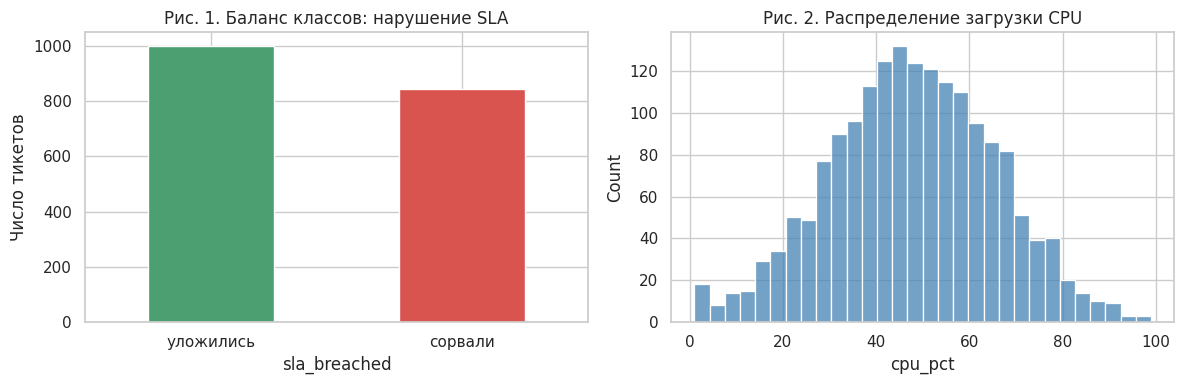

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_raw["sla_breached"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"]
)
axes[0].set_title("Рис. 1. Баланс классов: нарушение SLA")
axes[0].set_xticklabels(["уложились", "сорвали"], rotation=0)
axes[0].set_ylabel("Число тикетов")

sns.histplot(df_raw["cpu_pct"].dropna(), bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Рис. 2. Распределение загрузки CPU")
plt.tight_layout()
plt.show()


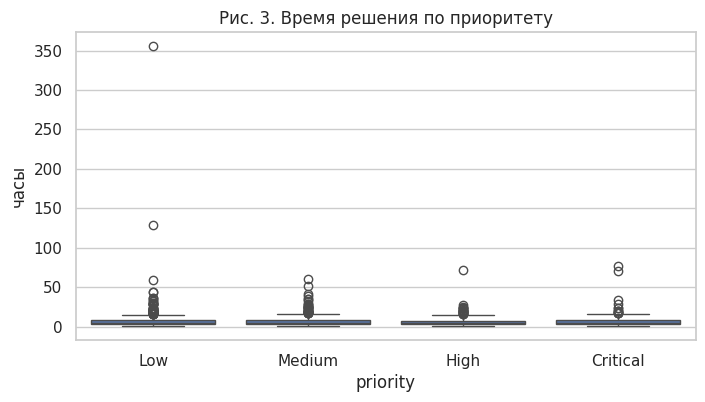

In [52]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="priority", y="resolve_hours",
            order=["Low", "Medium", "High", "Critical"], )
plt.title("Рис. 3. Время решения по приоритету")
plt.ylabel("часы")
plt.show()


### Задание 4

Постройте **не меньше четырёх разных типов** графиков по **своим** данным. Обязательно:

1. **Гистограмма** `resolve_hours` (видно ли выбросы справа?).
2. **Boxplot** `cpu_pct` в разрезе `sla_breached`.
3. **Тепловая карта** корреляций числовых столбцов (`corr(numeric_only=True)` + `sns.heatmap(..., annot=True)`).
4. **Столбчатая или круговая** диаграмма: доля нарушений SLA по `department` **или** по `product`.
5. По желанию пятый график (scatter `cpu_pct` vs `memory_mb`, stacked bar канала и SLA и т. п.).

После графиков напишите 2–3 вывода **по вашему SEED**, не общие фразы из учебника.


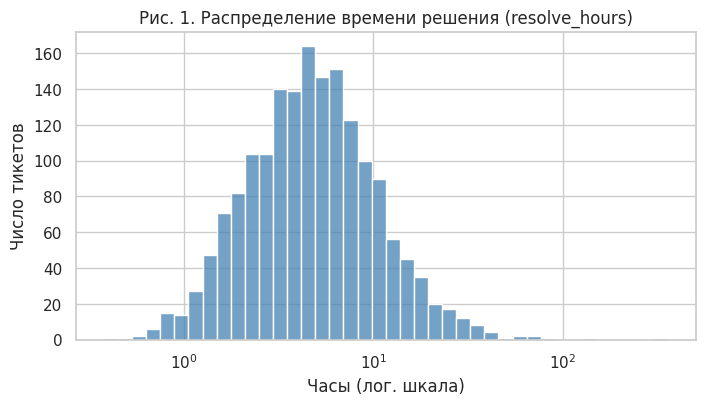

In [53]:
# ▼▼▼ ВАШ КОД (Задание 4) ▼▼▼

# График 1: гистограмма resolve_hours
plt.figure(figsize=(8, 4))
sns.histplot(df_raw["resolve_hours"], bins=40, log_scale=True, color="steelblue")
plt.title("Рис. 1. Распределение времени решения (resolve_hours)")
plt.xlabel("Часы (лог. шкала)")
plt.ylabel("Число тикетов")
plt.show()

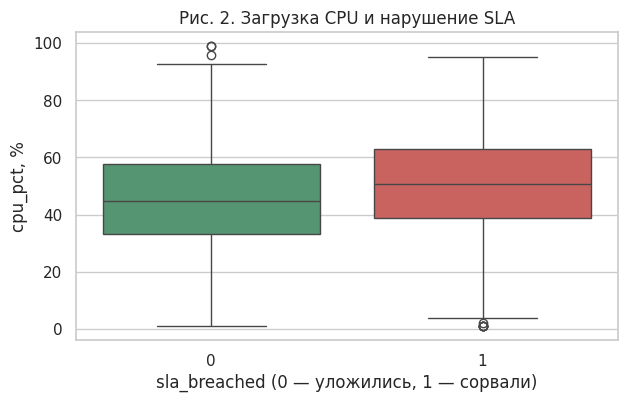

In [27]:
# График 2: boxplot cpu_pct по sla_breached
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_raw, x="sla_breached", y="cpu_pct", hue="sla_breached", palette=["#4C9F70", "#D9534F"], legend=False)
plt.title("Рис. 2. Загрузка CPU и нарушение SLA")
plt.xlabel("sla_breached (0 — уложились, 1 — сорвали)")
plt.ylabel("cpu_pct, %")
plt.show()

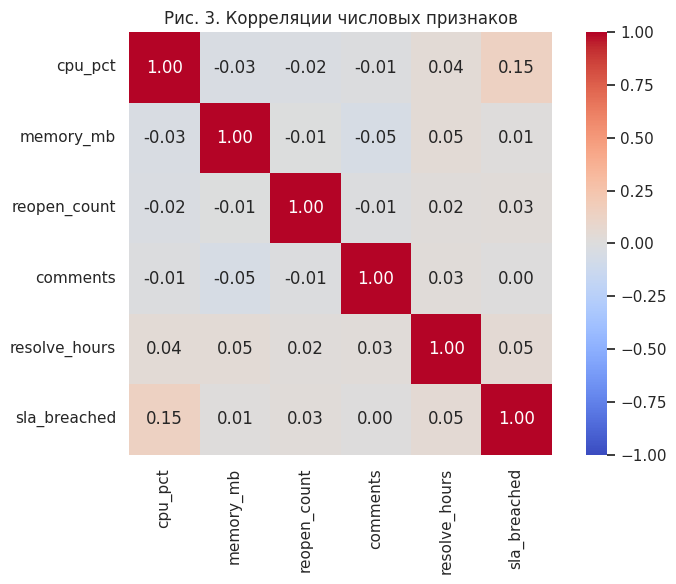

In [44]:
# График 3: тепловая карта корреляций (без идентификаторов и времени)
corr_cols = [
    "cpu_pct", "memory_mb", "reopen_count",
    "comments", "resolve_hours", "sla_breached",
]
corr = df_raw[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1, square=True,
)
plt.title("Рис. 3. Корреляции числовых признаков")
plt.tight_layout()
plt.show()

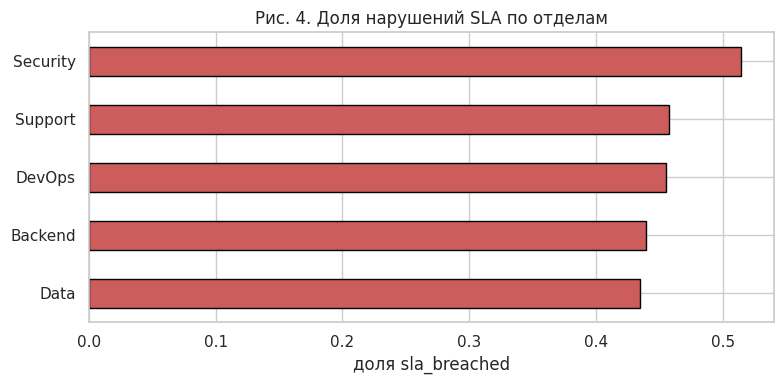

In [29]:
# График 4: доля SLA по отделу
dep_clean = df_raw["department"].astype(str).str.strip().str.title()
dep_clean = dep_clean.replace({"Devops": "DevOps"})

sla_by_dep = (
    df_raw.groupby(dep_clean)["sla_breached"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8, 4))
sla_by_dep.plot(kind="barh", color="indianred", edgecolor="black")
plt.title("Рис. 4. Доля нарушений SLA по отделам")
plt.xlabel("доля sla_breached")
plt.ylabel("")
plt.tight_layout()
plt.show()

priority
Low         33.7
Medium      42.5
High        57.6
Critical    77.2
Name: sla_breached, dtype: float64
product
Auth         44.5
Crm          44.6
Analytics    45.4
Cloud        47.1
Billing      47.5
Name: sla_breached, dtype: float64


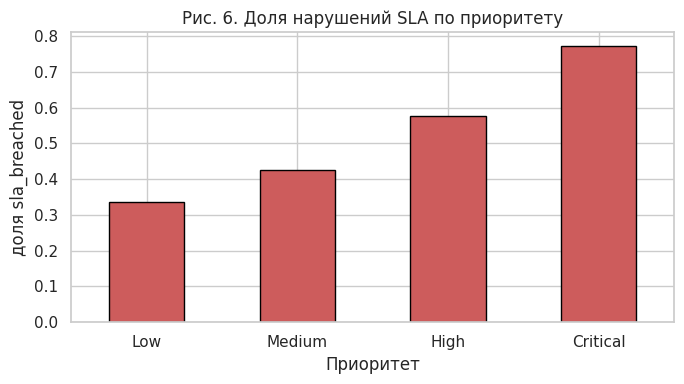

In [30]:
# Доля нарушений SLA по приоритету и продукту (текст очищен)
prio = df_raw.groupby("priority")["sla_breached"].mean().reindex(["Low", "Medium", "High", "Critical"])
print((prio * 100).round(1))

prod_clean = df_raw["product"].astype(str).str.strip().str.title()
print((df_raw.groupby(prod_clean)["sla_breached"].mean().sort_values() * 100).round(1))

plt.figure(figsize=(7, 4))
prio.plot(kind="bar", color="indianred", edgecolor="black")
plt.title("Рис. 6. Доля нарушений SLA по приоритету")
plt.xlabel("Приоритет")
plt.ylabel("доля sla_breached")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Выводы по графикам** :

1.Рост загрузки CPU связан с увеличением вероятности нарушения SLA. Корреляция составляет 0,15, а медианная загрузка CPU при нарушении SLA выше (около 50% против 45%).

2. Большинство числовых признаков слабо связаны между собой. Например, количество комментариев, повторных открытий и время решения практически не коррелируют с загрузкой CPU и нарушением SLA.

3. Высокая загрузка CPU не всегда приводит к нарушению SLA. На графике распределения загрузки CPU для обеих групп значительно пересекаются, поэтому нарушение SLA зависит не только от нагрузки на процессор.



**Контрольные вопросы к этапу 4:**

1. Что показывает boxplot и как по нему увидеть выброс?
2. Корреляция и причинно-следственная связь — в чём разница? Пример из IT-журнала.
3. Почему при редких нарушениях SLA одной accuracy на будущей модели может не хватить?


*Ответы:*

1. Boxplot показывает распределение числового признака в компактном виде: медиану (горизонтальная линия внутри ящика), нижний и верхний квартили (границы ящика), «усы» — линии, которые тянутся до минимального и максимального значения в пределах 1.5 межквартильного размаха от ящика. Точки за усами — это и есть кандидаты в выбросы: значения, которые настолько далеки от основной массы, что не помещаются в обычный размах. По нашему boxplot cpu_pct по sla_breached: если у одной группы точки-выбросы видны справа от верхнего уса, а у другой их нет, это значит, что у первой группы есть отдельные аномально загруженные узлы, которые сильно отличаются от типичной картины.

2. Корреляция и причинно-следственная связь — это не одно и то же, хотя в данных они часто идут рядом. Корреляция — статистическая характеристика: когда одна величина растёт, вторая тоже растёт (положительная) или падает (отрицательная), и насколько сильно эта связь выражена. Причинность — утверждение, что изменение одной величины вызывает изменение другой. В нашем журнале тикетов cpu_pct и sla_breached могут коррелировать, но это не значит, что высокая загрузка процессора сама по себе «ломает» SLA: обе величины могут расти из-за третьего фактора — например, из-за инцидента, который одновременно грузит узел и затягивает решение. Корреляция легко возникает и через случайное совпадение, и через общий знаменатель (оба признака зависят от длины тикета), и через обратную связь. Утверждать причинность можно только после контролируемого эксперимента или специального статистического анализа, а не по коэффициенту корреляции.

3. Если нарушения SLA встречаются редко, одной accuracy для оценки будущей модели не хватает, потому что она показывает долю верных ответов, а не то, насколько хорошо найден редкий класс. Пример: если нарушается 5 % тикетов, модель, которая всегда предсказывает «0» (SLA не нарушен), получит accuracy 95 % и при этом не найдёт ни одного реального нарушения. Для задачи, где важно заранее заметить срыв срока, это бесполезная модель с красивой метрикой. Поэтому используют precision (какая доля срабатываний оказалась настоящими нарушениями), recall (какую долю реальных нарушений модель поймала), F1 (их гармоническое среднее), а также ROC-AUC и PR-AUC, которые оценивают качество ранжирования тикетов по вероятности нарушения. При сильном перекосе классов PR-AUC обычно информативнее ROC-AUC, потому что ROC может выглядеть хорошо и у слабой модели. В нашем наборе ситуация мягче: доля нарушений составляет 45,8 %, то есть классы почти сбалансированы. Модель «всегда 0» дала бы accuracy около 54 %, и превзойти это значение уже заметно. Но даже здесь одной accuracy недостаточно: две модели с одинаковой точностью могут сильно отличаться по тому, сколько нарушений они пропускают, а цена пропущенного нарушения SLA и цена ложной тревоги в реальной службе поддержки обычно разные. Поэтому для итоговой оценки всё равно нужны precision, recall и F1.


---
# Этап 5. Подготовка данных и признаки (практика 5)

**Цель.** Убрать дубликаты, закрыть пропуски, привести текст к одному виду, закодировать категории, масштабировать числа, собрать несколько новых признаков. Это тот же конвейер, что на практике 5, только на вашем журнале тикетов.

Работайте с копией: исходный `df_raw` не затирайте.


### Пример


In [31]:
df = df_raw.copy()
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Удалено дубликатов:", before - df.shape[0])
print("Пропуски по столбцам:")
print(df.isna().sum())

median_cpu = df["cpu_pct"].median()
df["cpu_pct"] = df["cpu_pct"].fillna(median_cpu)
print("Пропусков в cpu_pct после заполнения:", int(df["cpu_pct"].isna().sum()))


Удалено дубликатов: 45
Пропуски по столбцам:
ticket_id           0
opened_ts           0
department          0
product             0
priority            0
channel             0
assignee_level      0
client_tier         0
cpu_pct            72
memory_mb           0
reopen_count        0
comments           54
resolve_hours     108
sla_breached        0
is_slow           108
dtype: int64
Пропусков в cpu_pct после заполнения: 0


In [32]:
# Текст: пробелы и регистр. Без этого Backend и BACKEND — разные категории.
demo = df["department"].astype(str).str.strip().str.title()
print("Уникальные отделы до:", df["department"].nunique())
print("После strip+title:", demo.nunique())
print(sorted(demo.unique()))


Уникальные отделы до: 10
После strip+title: 5
['Backend', 'Data', 'Devops', 'Security', 'Support']


### Задание 5

Начните заново с копии `df_raw`. Сохраните результат в `df_clean`, матрицу признаков в `X`, цель в `y`.

1. Удалите дубликаты.
2. Заполните пропуски: `resolve_hours` и `cpu_pct` — **медианой**, `comments` — **медианой** или нулём. Проверьте, что пропусков не осталось.
3. Приведите `department` и `product` к одному виду: `.str.strip()` и единый регистр (например `.str.title()`). Снова посчитайте число уникальных значений.
4. Закодируйте категории `department`, `product`, `priority`, `channel`, `assignee_level`, `client_tier` через `pd.get_dummies(...)`.
5. Создайте **не меньше трёх** осмысленных признаков, например:
   - `is_critical` — флаг приоритета Critical;
   - `load_score` — `cpu_pct * memory_mb / 1000`;
   - `reopen_rate` — `n_reopens / comments` (защититесь от деления на ноль);
   - свой признак (выходной ли день из `opened_ts`, «долгий тикет» и т. п.).
6. Отберите числовые столбцы (без `ticket_id` и `opened_ts`) и масштабируйте их `StandardScaler`. Сложите с dummy-признаками в `df_clean`.
7. Соберите `X` (всё, кроме `sla_breached` и идентификаторов) и `y = df_clean["sla_breached"]`. Напечатайте формы.


In [33]:
# ▼▼▼ ВАШ КОД (Задание 5) ▼▼▼
# 1–2. Дубликаты и пропуски
from sklearn.preprocessing import StandardScaler
df = df_raw.drop(columns=["is_slow"], errors="ignore").copy()

# 1. Удаление дубликатов
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print("Удалено дубликатов:", before - df.shape[0])

# 2. Заполнение пропусков
print("\nПропуски до:")
print(df.isna().sum())

df["resolve_hours"] = df["resolve_hours"].fillna(df["resolve_hours"].median())
df["cpu_pct"] = df["cpu_pct"].fillna(df["cpu_pct"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())

print("\nПропусков после:", int(df.isna().sum().sum()))


Удалено дубликатов: 45

Пропуски до:
ticket_id           0
opened_ts           0
department          0
product             0
priority            0
channel             0
assignee_level      0
client_tier         0
cpu_pct            72
memory_mb           0
reopen_count        0
comments           54
resolve_hours     108
sla_breached        0
dtype: int64

Пропусков после: 0


In [34]:
# 3. Текст department и product
print("department до:", sorted(df["department"].unique()))
print("product до:   ", sorted(df["product"].unique()))

df["department"] = df["department"].astype(str).str.strip().str.title()
df["product"] = df["product"].astype(str).str.strip().str.title()

print("\ndepartment после:", sorted(df["department"].unique()))
print("product после:   ", sorted(df["product"].unique()))
print("Уникальных department:", df["department"].nunique())
print("Уникальных product:   ", df["product"].nunique())

department до: ['BACKEND', 'Backend', 'DATA', 'DEVOPS', 'Data', 'DevOps', 'SECURITY', 'SUPPORT', 'Security', 'Support']
product до:    ['  analytics ', '  auth ', '  billing ', '  cloud ', '  crm ', 'Analytics', 'Auth', 'Billing', 'CRM', 'Cloud']

department после: ['Backend', 'Data', 'Devops', 'Security', 'Support']
product после:    ['Analytics', 'Auth', 'Billing', 'Cloud', 'Crm']
Уникальных department: 5
Уникальных product:    5


In [35]:
# 4. get_dummies
cat_cols = ["department", "product", "priority", "channel", "assignee_level", "client_tier"]

df_clean = pd.get_dummies(df, columns=cat_cols)
print("Размер после get_dummies:", df_clean.shape)
print("Столбцов-пустышек:", len([c for c in df_clean.columns if c.endswith("_")]))

Размер после get_dummies: (1800, 32)
Столбцов-пустышек: 0


In [36]:
# 5. Новые признаки (минимум 3, один — свой)

# is_critical: флаг приоритета Critical
if "priority_Critical" in df_clean.columns:
    df_clean["is_critical"] = df_clean["priority_Critical"].astype(int)
else:
    df_clean["is_critical"] = (df["priority"] == "Critical").astype(int).values

# load_score: нагрузка «CPU × память»
df_clean["load_score"] = df_clean["cpu_pct"] * df_clean["memory_mb"] / 1000

# reopen_rate: доля повторных открытий от числа комментариев
comments_safe = df_clean["comments"].replace({0: np.nan})
df_clean["reopen_rate"] = (
    df_clean["reopen_count"] / comments_safe
).fillna(0)

# свой признак: тикет открыт в выходной
df_clean["opened_at"] = pd.to_datetime(df_clean["opened_ts"], unit="s")
df_clean["is_weekend"] = (df_clean["opened_at"].dt.dayofweek >= 5).astype(int)

print("Новые признаки:")
display(df_clean[["is_critical", "load_score", "reopen_rate", "is_weekend"]].head())

Новые признаки:


,is_critical,load_score,reopen_rate,is_weekend
0,0,58.6971,0.166667,0
1,0,63.4508,0.000000,0
2,1,118.0488,0.200000,0
3,0,100.5731,0.000000,0
4,0,116.3120,0.333333,0


In [54]:
from sklearn.preprocessing import StandardScaler

# 6. Масштабирование числовых столбцов (результат заменяет исходные)
num_for_scale = [
    "cpu_pct", "memory_mb", "reopen_count", "comments",
    "resolve_hours", "load_score", "reopen_rate",
]
scaler = StandardScaler()
df_clean[num_for_scale] = scaler.fit_transform(df_clean[num_for_scale])
print("Размер df_clean:", df_clean.shape)
print("Пропусков в df_clean:", int(df_clean.isna().sum().sum()))

Размер df_clean: (1800, 37)
Пропусков в df_clean: 0


In [38]:
# 7. Сборка X и y
drop_cols = ["sla_breached", "ticket_id", "opened_ts", "opened_at"]
X = (
    df_clean
    .drop(columns=[c for c in drop_cols if c in df_clean.columns])
    .select_dtypes(include=[np.number, bool])
    .astype(float)
)
y = df_clean["sla_breached"]
print("Размер X:", X.shape, "| Размер y:", y.shape)
print("Пропусков в X:", int(X.isna().sum().sum()))

Размер X: (1800, 33) | Размер y: (1800,)
Пропусков в X: 0


**Контрольные вопросы к этапу 5:**

1. Когда для пропусков берут медиану, а когда среднее?
2. Что такое One-Hot (`get_dummies`) и почему отделы нельзя просто заменить числами 1, 2, 3…?
3. Зачем масштабировать признаки перед линейными моделями и kNN и почему дереву это обычно не нужно?
4. Почему `ticket_id` нельзя подавать в модель как обычный признак?


*Ответы:*

1. Медиану для пропусков берут, когда в столбце возможны выбросы или распределение сильно скошено — она устойчива к крайним значениям, потому что зависит от положения «середины», а не от суммы всех значений. Среднее, наоборот, чувствительно к выбросам: один тикет с resolve_hours = 2000 сильно сдвинет среднее, хотя типичное время решения — несколько часов. В нашем resolve_hours явно правый хвост из-за того, что в генераторе 10 случайных тикетов умножены на 9, поэтому медиана здесь безопаснее. Среднее уместно, когда распределение примерно симметрично и крайних значений нет — например, для нормально распределённой cpu_pct. Дополнительное правило: медиану берут для непрерывных величин с длинным хвостом, моду — для категориальных, а если пропусков очень мало и они случайны, иногда просто удаляют строки.

2. One-Hot-кодирование (pd.get_dummies) создаёт для каждой категории отдельный 0/1-столбец. Если категорий пять, появится пять новых столбцов, в каждом из которых единица стоит только там, где в исходной строке была именно эта категория. Отделы нельзя просто заменить числами 1, 2, 3…, потому что между отделами нет порядка. Если мы закодируем Support = 1, Backend = 2, DevOps = 3, то алгоритм начнёт считать, что Support меньше Backend, Backend меньше DevOps, и «расстояние» между Support и DevOps в два раза больше, чем между Support и Backend. Для линейных моделей это означает, что коэффициент признака department будет трактоваться как «чем больше число, тем сильнее эффект», хотя это бессмыслица. Для деревьев это тоже портит разбиения: они будут пытаться отделить «большие» номера от «маленьких», хотя реальные категории между собой не упорядочены. One-Hot убирает эту ложную арифметику: каждая категория — независимый признак.

3. Масштабирование признаков нужно, потому что у разных столбцов разный диапазон. memory_mb может быть в сотнях и тысячах, а cpu_pct — в десятках. В линейных моделях и kNN это критично: в kNN расстояние между точками считается по всем осям сразу, и столбец с большим разбросом перетягивает всё расстояние на себя, полностью «заглушая» столбцы с маленьким разбросом. В линейных моделях коэффициенты тоже получаются несопоставимыми: чтобы признак с малым разбросом влиял так же, как признак с большим, его коэффициент должен быть в разы больше — это мешает интерпретации и ломает регуляризацию. Деревья решают, какой признак взять на разбиение, по одному столбцу за раз и пороги ищут по значениям этого столбца независимо от других. Масштаб на это не влияет, поэтому дереву масштабирование обычно не нужно — это экономит время и не даёт никакого прироста качества.

4. ticket_id нельзя подавать в модель как обычный признак, потому что в нём нет никакой связи с целевой переменной. Это просто номер строки в базе — уникальный для каждого тикета. Если дать его модели, произойдёт одна из двух вещей. Либо модель (особенно деревья) запомнит отдельные номера, на которых в обучающей выборке sla_breached = 1, и на новых тикетах, где таких номеров не будет, ничего путного не предскажет — это классическое переобучение на шум. Либо, если ticket_id случайно коррелирует с чем-то (например, более поздние тикеты чаще старые и у них другой SLA), модель выучит ложную закономерность, которая исчезнет при следующей выгрузке. Есть отдельный подводный камень: если ticket_id возрастает со временем, он неявно кодирует время, и модель может «подсмотреть» за ним тренды, которые в реальной эксплуатации не повторятся. Поэтому идентификаторы всегда убирают из матрицы признаков — они либо не входят в X, либо остаются отдельным столбцом для отслеживания, но не участвуют в обучении.


In [39]:
df_raw.shape[0]
df_clean.shape[0]
f"{df_raw['sla_breached'].mean():.4f}"
f"({df_raw['sla_breached'].mean():.1%})"
X.shape
# SEED

(1800, 33)

---
# Итоговый отчёт студента


### Данные варианта

| Поле | Значение |
|------|----------|
| ФИО | Бокерия Полина Георгиевна |
| Номер по списку | 4 |
| Персональный SEED | 92977 |
| Строк в `df_raw` | 1845 |
| Строк после удаления дубликатов | 1800 |
| Доля `sla_breached` | 45.8% |
| Размер `X` (строки × столбцы) | (1800, 33) |

### Кратко по этапам

1. Что необычного увидели при осмотре (типы, дубликаты, пропуски)?

В df_raw 1845 строк и 14 столбцов. Пропуски есть в трёх полях: resolve_hours (около 6 %), cpu_pct (около 4 %) и comments (около 3 %). Полных дубликатов 45, после их удаления осталось 1800 строк. Текстовые столбцы «грязные»: в department есть варианты BACKEND, SUPPORT и т. п. в верхнем регистре, в product встречаются лишние пробелы и нижний регистр, из-за чего вместо пяти категорий получалось по десять, пока текст не был приведён к единому виду. В числовых столбцах есть выбросы: resolve_hours доходит примерно до 355 часов при медиане около 4,7, а memory_mb до 25 886 МБ при типичных значениях около 2200. Доля нарушений SLA составляет 45,8 %, то есть классы почти сбалансированы.

2. Какой отдел / продукт / приоритет чаще ломает SLA на ваших графиках?

Приоритет влияет сильнее всего: у Critical нарушено 77,2 % тикетов, у High 57,6 %, у Medium 42,5 %, у Low только 33,7 % (Рис. 6). По отделам хуже всего Security (около 51,5 % нарушений), лучше всего Data (около 43,5 %), разброс небольшой (Рис. 4). По продуктам различия ещё меньше: самый проблемный Billing (47,5 %), самый благополучный Auth (44,5 %), поэтому уверенного вывода по продукту сделать нельзя. По корреляциям с sla_breached (Рис. 3) заметна только загрузка CPU (r ≈ 0,15), у resolve_hours связь очень слабая (r ≈ 0,05), у остальных числовых признаков она близка к нулю. Значит, нарушение SLA определяется в первую очередь приоритетом тикета, а не одним числовым показателем.

3. Какие три новых признака сделали и зачем?

is_critical — флаг приоритета Critical, потому что это самый сильный фактор по разведочному анализу (77,2 % нарушений против 33,7 % у Low). load_score = cpu_pct * memory_mb / 1000 — обобщённая нагрузка узла, объединяет два связанных показателя. reopen_rate = reopen_count / comments — частота повторных открытий относительно активности в тикете, с защитой от деления на ноль (при comments = 0 признак равен 0). Дополнительно добавила свой признак is_weekend (тикет открыт в выходной): гипотеза состояла в том, что в выходные реакция дежурной смены может быть медленнее. По данным разница небольшая (около 44,8 % нарушений в будни и 47,6 % в выходные), поэтому полезность признака нужно проверять уже при построении модели.


### Финальная самопроверка

Ячейка ниже не ставит оценку, а подсказывает, какие переменные ещё не созданы.


In [40]:
problems = []

if "SEED" not in dir():
    problems.append("Не вычислен SEED (шаг 0).")
if "df_raw" not in dir():
    problems.append("Не создан df_raw (генерация датасета).")
if "df_clean" not in dir() or df_clean is None:
    problems.append("Не создан df_clean (этап 5).")
if "X" not in dir() or X is None:
    problems.append("Не создана матрица X (этап 5).")
if "y" not in dir() or y is None:
    problems.append("Не создан вектор y (этап 5).")
if "df_clean" in dir() and df_clean is not None:
    n_na = int(df_clean.isna().sum().sum())
    if n_na > 0:
        problems.append(f"В df_clean ещё есть пропуски: {n_na}.")

if problems:
    print("Ещё не готово:")
    for item in problems:
        print(" -", item)
else:
    print("Базовые переменные на месте. Проверьте текстовые ответы и отчёт.")
    print("SEED:", SEED, "| X:", X.shape, "| y:", y.shape)


Базовые переменные на месте. Проверьте текстовые ответы и отчёт.
SEED: 92977 | X: (1800, 33) | y: (1800,)


---
### Как сдать работу

1. Запустите все ячейки **сверху вниз** без ошибок (`Среда выполнения → Перезапустить и выполнить всё`).
2. Заполните код заданий, контрольные вопросы и итоговый отчёт.
3. Сохраните файл: `Файл → Скачать → Скачать .ipynb`.
4. Переименуйте в `Фамилия_Имя_ПР6.ipynb` и загрузите в Moodle.

Шкала: 5 блоков = **14 баллов**. Пустой шаблон без запуска не оценивается.
